# Task 3.2 — Alertas tempranas de colapso con ruido estocástico
**Grupo 3:** $b=0.58$. Trabajo reproducible de incisos **(b)–(f)**. El inciso (a) se desarrolla a mano.

**Criterios:** Euler–Maruyama $dt=0.05$, $\sigma=0.01$, carga inicial $a_0=0.5a_{col}$, $a(t)=a_0+vt$ y $a(2000)=a_{col}$. Para detectar el salto se usa el cruce del umbral de concentración $x=1$; se registra la elección y se verifica visualmente. La autocorrelación de retardo uno corresponde a $\Delta t=dt$.

**Aviso:** las estimaciones dependen de la semilla, la ventana y el criterio de salto. Se distinguen las predicciones de la aproximación OU y los valores observados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import kendalltau

B = 0.58
DT = 0.05
SIGMA = 0.01
T_TARGET = 2000.0
SEED = 23617
N_REAL = 100
WINDOW_TIME = 150.0       # justificación: suficientemente larga para estimar estadísticos locales
STEP_TIME = 20.0          # ventanas solapadas para observar tendencias graduales
JUMP_THRESHOLD = 1.0     # distinguir salto hacia estado de alta concentración

def g(x): return B*x - x*x/(1+x*x)
def gprime(x): return B - 2*x/(1+x*x)**2
def f(x, a): return a - g(x)

x_col = brentq(gprime, 0.20, 0.60)
x_rec = brentq(gprime, 0.60, 1.15)
a_col, a_rec = g(x_col), g(x_rec)
a0 = 0.5*a_col
v = (a_col-a0)/T_TARGET
x0 = brentq(lambda x: g(x)-a0, 0, x_col)
print(f'x_col={x_col:.9f}, a_col={a_col:.9f}; x_rec={x_rec:.9f}, a_rec={a_rec:.9f}')
print(f'a0={a0:.9f}, v={v:.12f}, x0={x0:.9f}')
print(f'Parámetros: sigma={SIGMA}, dt={DT}, horizonte nominal={T_TARGET}')

x_col=0.379594452, a_col=0.094220405; x_rec=0.834430585, a_rec=0.073496999
a0=0.047110202, v=0.000023555101, x0=0.097440662
Parámetros: sigma=0.01, dt=0.05, horizonte nominal=2000.0


## (b) Simulación Euler–Maruyama

El esquema numérico es $x_{n+1}=x_n+f(x_n;a_n)\,dt+\sigma\sqrt{dt}\,Z_n$, con $Z_n\sim N(0,1)$. Se permite un margen adicional de tiempo tras $t=2000$ para registrar un salto que se retrase por la dinámica estocástica (la carga sigue subiendo). El umbral elegido no reemplaza el punto crítico teórico.

Salto detectado en t=2062.95, a=0.0957032


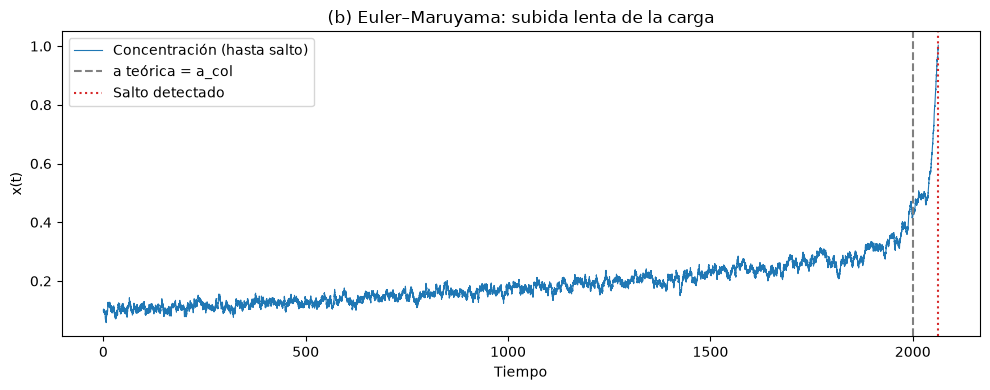

In [2]:
def simulate_ensemble(n, sigma=SIGMA, rise_time=T_TARGET, constant=False, seed=SEED,
                      extra_time=1000.0):
    rng = np.random.default_rng(seed)
    horizon = rise_time + (0 if constant else extra_time)
    times = np.arange(int(np.ceil(horizon/DT))+1)*DT
    slope = 0.0 if constant else (a_col-a0)/rise_time
    path = np.empty((n, len(times)), dtype=np.float32)
    path[:, 0] = x0
    hits = np.full(n, -1, dtype=int)
    states = np.full(n, x0, dtype=float)
    for k in range(1, len(times)):
        aa = a0+slope*times[k-1]
        states = states + (aa - B*states + states**2/(1+states**2))*DT + sigma*np.sqrt(DT)*rng.standard_normal(n)
        path[:, k] = states
        newly = (hits < 0) & (states >= JUMP_THRESHOLD)
        hits[newly] = k
    return times, path, hits, slope

times, paths, hits, slope = simulate_ensemble(1)
first_jump = hits[0]
if first_jump < 0:
    print('No se detectó salto dentro del horizonte extendido. Aumentar extra_time si se desea.')
    endpoint = len(times)
else:
    print(f'Salto detectado en t={times[first_jump]:.2f}, a={a0+slope*times[first_jump]:.7f}')
    endpoint = first_jump
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times[:endpoint+1], paths[0, :endpoint+1], lw=.8, label='Concentración (hasta salto)')
ax.axvline(T_TARGET, ls='--', color='gray', label='a teórica = a_col')
if first_jump >= 0: ax.axvline(times[first_jump], color='tab:red', ls=':', label='Salto detectado')
ax.set(xlabel='Tiempo', ylabel='x(t)', title='(b) Euler–Maruyama: subida lenta de la carga')
ax.legend(); fig.tight_layout(); plt.show()

## (c) Tendencia eliminada, indicadores y curvas teóricas

**Destendenciado:** se ajusta por mínimos cuadrados una recta en cada ventana móvil y se restan sus valores. Esto elimina la deriva aproximadamente lineal de la media causada por el cambio lento de $a$. Se utiliza una ventana de **150 unidades de tiempo**, con saltos de **20 unidades**; la desviación estándar se estima con `ddof=1`, y la autocorrelación lag-1 como correlación de Pearson entre residuos consecutivos.

El modelo OU local predice $\operatorname{Var}(y)=\sigma^2/(2\kappa)$ y $\rho_1=e^{-\kappa dt}$, con $\kappa=g'(x^*(a))$. Se muestra varianza, no desviación estándar, para comparar unidades coherentes. La teoría solo se representa donde existe el equilibrio estable inferior y $\kappa>0$.

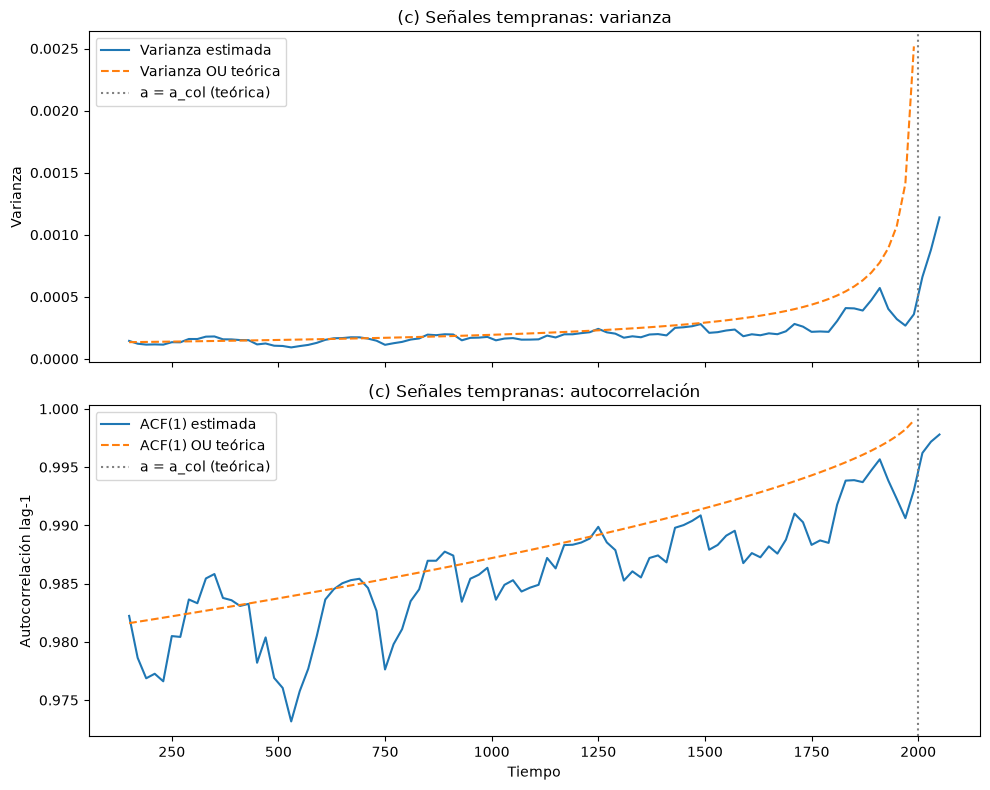

 tiempo  varianza     acf1
1909.95  0.000571 0.995669
1929.95  0.000402 0.993847
1949.95  0.000320 0.992259
1969.95  0.000268 0.990618
1989.95  0.000359 0.993018
2009.95  0.000660 0.996216
2029.95  0.000879 0.997179
2049.95  0.001140 0.997798


In [3]:
WINDOW = int(round(WINDOW_TIME/DT))
STRIDE = int(round(STEP_TIME/DT))

from numba import njit

@njit
def _indicator_fast(x, dt, win, stride, end):
    n = max(0, (end-win)//stride + 1)
    out = np.empty((n,3),dtype=np.float64)
    zm = (win-1)*0.5
    den = win*(win*win-1)/12.0
    for j in range(n):
        right=win+j*stride
        mean=0.0
        for k in range(win):mean+=x[right-win+k]
        mean/=win
        cov=0.0
        for k in range(win): cov+=(k-zm)*(x[right-win+k]-mean)
        sl=cov/den
        rs=0.0; lag=0.0; first=0.0; last=0.0
        for k in range(win):
            res=x[right-win+k]-mean-sl*(k-zm)
            rs+=res*res
            if k==0:first=res
            if k==win-1:last=res
            if k>0:
                prev=x[right-win+k-1]-mean-sl*(k-1-zm)
                lag+=prev*res
        var=rs/(win-1)
        # Correlación de Pearson lag-1: centrar ambas series de residuos.
        avg1=-last/(win-1);avg2=-first/(win-1)
        covlag=lag-(win-1)*avg1*avg2
        ss1=rs-last*last-(win-1)*avg1*avg1
        ss2=rs-first*first-(win-1)*avg2*avg2
        corr=covlag/np.sqrt(ss1*ss2) if ss1>0 and ss2>0 else np.nan
        out[j,0]=(right-1)*dt;out[j,1]=var;out[j,2]=corr
    return out

def indicators(t,x,stop_index=None):
    end=len(t) if stop_index is None or stop_index<0 else int(stop_index)
    out=_indicator_fast(np.asarray(x),DT,WINDOW,STRIDE,end)
    return pd.DataFrame(out,columns=['tiempo','varianza','acf1'])

def theoretical(t, slope, sigma):
    theoretical_v = np.full_like(t, np.nan, dtype=float)
    theoretical_ac = np.full_like(t, np.nan, dtype=float)
    for i, ti in enumerate(t):
        aa = a0+slope*ti
        if aa < a_col-1e-10:
            stable_x = brentq(lambda x: g(x)-aa, 0, x_col)
            kappa = gprime(stable_x)
            theoretical_v[i] = sigma**2/(2*kappa)
            theoretical_ac[i] = np.exp(-kappa*DT)
    return theoretical_v, theoretical_ac

obs = indicators(times, paths[0], first_jump)
theory_var, theory_ac = theoretical(obs.tiempo.to_numpy(), slope, SIGMA)
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(obs.tiempo, obs.varianza, label='Varianza estimada')
axes[0].plot(obs.tiempo, theory_var, '--', label='Varianza OU teórica')
axes[0].set(ylabel='Varianza', title='(c) Señales tempranas: varianza')
axes[1].plot(obs.tiempo, obs.acf1, label='ACF(1) estimada')
axes[1].plot(obs.tiempo, theory_ac, '--', label='ACF(1) OU teórica')
axes[1].set(xlabel='Tiempo', ylabel='Autocorrelación lag-1', title='(c) Señales tempranas: autocorrelación')
for ax in axes:
    ax.axvline(T_TARGET, ls=':', color='gray', label='a = a_col (teórica)')
    ax.legend()
fig.tight_layout();plt.show()
print(obs.tail(8).to_string(index=False))

## (d) 100 realizaciones: Kendall $\tau$

Para cada realización, sobre los indicadores previos al salto, se calcula Kendall $\tau$ entre el tiempo y **la varianza**, y, adicionalmente, entre el tiempo y **la autocorrelación**. Se considera alerta positiva significativa cuando $\tau>0$ y $p<0.05$ (p bilateral de `scipy.stats.kendalltau`, criterio conservador para una tendencia positiva). Se reportan ambas tasas por separado y la alerta conjunta (`ambas`). **Advertencia estadística:** las ventanas solapadas generan dependencia, por lo que estos p-valores son aproximados y pueden ser anticonservadores.

In [4]:
def assess_indicators(t, paths, hits):
    rows = []
    for i in range(paths.shape[0]):
        metrics = indicators(t, paths[i], hits[i])
        result = {'realizacion': i+1, 't_salto': float(t[hits[i]]) if hits[i]>=0 else np.nan,
                  'n_ventanas': len(metrics)}
        for key in ['varianza','acf1']:
            if len(metrics)>=8 and np.all(np.isfinite(metrics[key])):
                tau,p = kendalltau(metrics.tiempo,metrics[key])
            else: tau,p=np.nan,np.nan
            result[f'tau_{key}']=tau;result[f'p_{key}']=p
            result[f'alerta_{key}']=bool(np.isfinite(tau) and tau>0 and p<.05)
        result['alerta_ambas']=result['alerta_varianza'] and result['alerta_acf1']
        rows.append(result)
    return pd.DataFrame(rows)

def summarize(df, name):
    print(f'\n{name}  (n={len(df)}, saltos detectados={df.t_salto.notna().sum()})')
    for k in ['varianza','acf1','ambas']:
        print(f'  Alerta {k:9s}: {df[f"alerta_{k}"].mean():.1%}')
    print(f'  Realizaciones con >=8 ventanas: {(df.n_ventanas>=8).mean():.1%}')

ensemble_t, ensemble_x, ensemble_hits, _ = simulate_ensemble(N_REAL,seed=SEED+1)
results_rise = assess_indicators(ensemble_t,ensemble_x,ensemble_hits)
summarize(results_rise, '(d) Carga creciente')
display(results_rise.head(10))


(d) Carga creciente  (n=100, saltos detectados=100)
  Alerta varianza : 100.0%
  Alerta acf1     : 100.0%
  Alerta ambas    : 100.0%
  Realizaciones con >=8 ventanas: 100.0%


,realizacion,t_salto,n_ventanas,tau_varianza,p_varianza,alerta_varianza,tau_acf1,p_acf1,alerta_acf1,alerta_ambas
0,1,2100.55,98,0.663791,3.538833e-22,True,0.704187,9.331026e-25,True,True
1,2,2116.15,99,0.572459,4.649159e-17,True,0.591012,4.423746e-18,True,True
2,3,2067.65,96,0.672368,2.881899e-22,True,0.666228,6.845525e-22,True,True
3,4,2062.05,96,0.584211,3.392805e-17,True,0.586404,2.587286e-17,True,True
4,5,2146.95,100,0.574545,2.458904e-17,True,0.573333,2.866112e-17,True,True
5,6,2065.25,96,0.601754,3.774117e-18,True,0.597368,6.573990e-18,True,True
6,7,2123.50,99,0.658627,4.505996e-22,True,0.646259,2.603745e-21,True,True
7,8,2093.50,98,0.545971,1.654469e-15,True,0.551862,8.227239e-16,True,True
8,9,2135.45,100,0.675960,2.173572e-23,True,0.692525,1.807468e-24,True,True
9,10,2021.35,94,0.497140,1.269359e-12,True,0.498055,1.154796e-12,True,True


## (e) Control: carga constante

La carga permanece en $a=0.5a_{col}$ durante **2000 unidades de tiempo**. Sin colapso real, cualquier alerta significativa es un **falso positivo**. Se usa el mismo procedimiento y parámetros de análisis que en (d).

In [5]:
ctl_t, ctl_x, ctl_hits, _ = simulate_ensemble(N_REAL, constant=True,seed=SEED+2)
results_control = assess_indicators(ctl_t, ctl_x, ctl_hits)
summarize(results_control, '(e) Control estacionario / falsas alarmas')
print('Interpretación: una fracción positiva más elevada en el control reduce la especificidad del indicador.')


(e) Control estacionario / falsas alarmas  (n=100, saltos detectados=0)
  Alerta varianza : 14.0%
  Alerta acf1     : 16.0%
  Alerta ambas    : 14.0%
  Realizaciones con >=8 ventanas: 100.0%
Interpretación: una fracción positiva más elevada en el control reduce la especificidad del indicador.


## (f) Sensibilidad: doble ruido y subida dos veces más rápida

Se repiten las 100 realizaciones para $\sigma=0.02$, y luego para una rampa que alcanza $a_{col}$ en **1000** unidades de tiempo. Se mantiene la misma ventana física de 150 unidades, el paso 20 y $dt=0.05$.

**Predicciones:** duplicar $\sigma$ multiplica por **4** la varianza OU mientras que $\rho_1$ teórica no depende directamente de $\sigma$. Aumentar $v$ reduce el tiempo de adaptación cuasiestacionaria, haciendo que la teoría de equilibrio instantáneo sea menos exacta y pudiendo retrasar el salto.


(f) Doble ruido  (n=100, saltos detectados=100)
  Alerta varianza : 100.0%
  Alerta acf1     : 100.0%
  Alerta ambas    : 100.0%
  Realizaciones con >=8 ventanas: 100.0%

(f) Subida dos veces más rápida  (n=100, saltos detectados=100)
  Alerta varianza : 99.0%
  Alerta acf1     : 99.0%
  Alerta ambas    : 99.0%
  Realizaciones con >=8 ventanas: 100.0%


,Escenario,N,Salto detectado,Alerta varianza (%),Alerta ACF1 (%),Ambas (%),Mediana t salto
0,"Base, sigma=0.01",100,100,100.0,100.0,100.0,2108.55
1,"Control, a fija",100,0,14.0,16.0,14.0,NaN
2,"Ruido duplicado, sigma=0.02",100,100,100.0,100.0,100.0,2038.15
3,"Rampa rápida, T=1000",100,100,99.0,99.0,99.0,1093.23


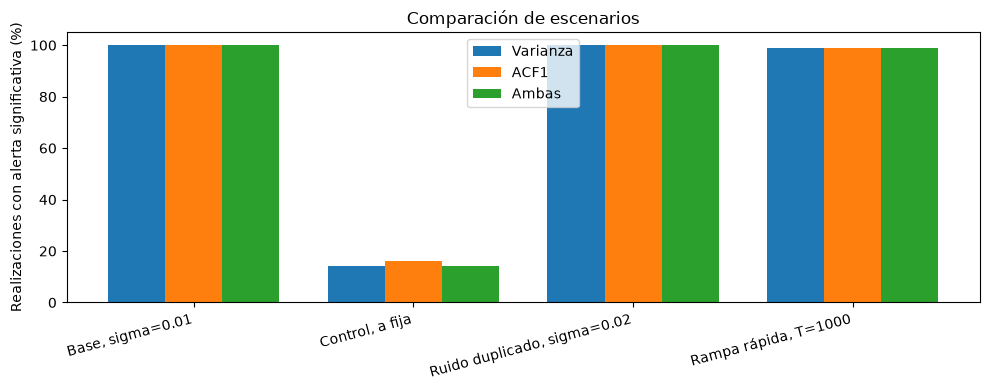

Se guardaron tablas CSV con resultados reales de la ejecución.


In [6]:
noise_t, noise_x, noise_hits, _ = simulate_ensemble(N_REAL,sigma=2*SIGMA,seed=SEED+3)
results_noise = assess_indicators(noise_t, noise_x,noise_hits)
summarize(results_noise,'(f) Doble ruido')

fast_t, fast_x, fast_hits, _ = simulate_ensemble(N_REAL,rise_time=T_TARGET/2,seed=SEED+4)
results_fast = assess_indicators(fast_t,fast_x,fast_hits)
summarize(results_fast,'(f) Subida dos veces más rápida')

comparison=[]
for title,df in [('Base, sigma=0.01', results_rise),('Control, a fija',results_control),
                 ('Ruido duplicado, sigma=0.02',results_noise),('Rampa rápida, T=1000',results_fast)]:
    comparison.append({'Escenario':title,'N':len(df),'Salto detectado':int(df.t_salto.notna().sum()),
                       'Alerta varianza (%)':round(100*df.alerta_varianza.mean(),1),
                       'Alerta ACF1 (%)':round(100*df.alerta_acf1.mean(),1),
                       'Ambas (%)':round(100*df.alerta_ambas.mean(),1),
                       'Mediana t salto':round(df.t_salto.median(),2) if df.t_salto.notna().any() else np.nan})
summary_table = pd.DataFrame(comparison)
display(summary_table)
fig, ax = plt.subplots(figsize=(10,4))
xlabels = summary_table.Escenario.tolist(); xpos=np.arange(len(xlabels)); w=.26
for j,(column, title) in enumerate([('Alerta varianza (%)','Varianza'),('Alerta ACF1 (%)','ACF1'),('Ambas (%)','Ambas')]):
    ax.bar(xpos+(j-1)*w, summary_table[column],width=w,label=title)
ax.set_xticks(xpos,xlabels,rotation=15,ha='right');ax.set(ylabel='Realizaciones con alerta significativa (%)',ylim=(0,105),title='Comparación de escenarios')
ax.legend();fig.tight_layout();plt.show()
summary_table.to_csv('Task3_2_resumen.csv',index=False)
results_rise.to_csv('Task3_2_realizaciones_base.csv',index=False)
results_control.to_csv('Task3_2_realizaciones_control.csv',index=False)
results_noise.to_csv('Task3_2_realizaciones_doble_ruido.csv',index=False)
results_fast.to_csv('Task3_2_realizaciones_rampa_rapida.csv',index=False)
print('Se guardaron tablas CSV con resultados reales de la ejecución.')

## Conclusiones para el reporte (completar con la tabla ejecutada)

- **(b)** Comparar el tiempo de salto detectado con $t=2000$ y distinguir un salto precoz por ruido de un retraso dinámico.
- **(c)** Comparar las curvas teóricas con los estimadores móviles; la teoría OU supone pequeña perturbación, $a$ casi constante y equilibrio local estable.
- **(d)** Reportar las fracciones de la tabla para varianza y ACF1, y explicar que una tendencia significativa es una señal estadística, no certeza de colapso.
- **(e)** El porcentaje de alertas del control estima empíricamente los falsos positivos bajo la definición elegida; con ventanas solapadas la prueba de Kendall no asegura nominalmente un 5 % exacto.
- **(f)** La varianza teórica se cuadruplica al duplicar $\sigma$; la autocorrelación OU no cambia directamente. Aumentar la velocidad viola más el supuesto de cambio lento, reduciendo el tiempo disponible para observar señales y alterando el momento de salto.

**Reproducibilidad:** semilla fija, código abierto en este notebook, todos los umbrales y tiempos parametrizados. No se fabricaron datos.